In [1]:
%pip install numpy matplotlib scipy > /dev/null
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
import kalman
kalman.set_debug(0)


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Combinatorial Kalman Filter — Track Finding

Most Kalman filters track one trajectory from a stream of single measurements. A
particle detector poses a harder problem.

Each detector layer records many hits. Some hits come from real particles. Some hits
come from background noise. The filter does not know in advance which hit belongs to
which track. This makes track reconstruction a combinatorial problem.

The Combinatorial Kalman Filter (CKF) solves this problem by track following. It
starts from a seed and walks outward layer by layer. At each layer, the CKF performs
four steps:

1. **Predict.** The filter predicts where the track should cross the next layer. It
   does this with a Kalman predict step through the magnetic field.
2. **Gate and branch.** The filter tests every hit on that layer with the innovation
   $\chi^2$. It opens a **branch** for each hit that passes the test. It also opens a
   *hole* branch, for the case where the detector missed the hit.
3. **Prune.** The filter prunes the growing tree of candidate tracks. It keeps only a
   bounded beam of the best candidates.
4. **Arbitrate.** The filter resolves hits that are shared between candidates. This
   step makes the final tracks disjoint.

Modern particle trackers use this algorithm. One example is Belle II
([BELLE2-PTHESIS-2019-002](https://docs.belle2.org/files/4163/BELLE2-PTHESIS-2019-002/1/BELLE2-PTHESIS-2019-002.pdf)).

This notebook runs the CKF on a simple 2-D tracker. A charged particle bends in a
uniform magnetic field $B_z$. The tracker samples the particle's path on concentric
cylindrical layers. This setup is a simplified model of a real drift chamber (CDC).


## Step 1 — Define the Detector Model

`DriftChamberModel` represents the detector and the particle physics.

The state is $x = [x, y, p_x, p_y]$: the transverse position and momentum. The
magnetic field bends the trajectory into a circular arc. The curvature of this arc is
$1/R = qB_z/|p|$.

The propagation function `f(x, t=r)` advances the arc to the next layer radius $r$.
The measurement function `h(x) = [x, y]` gives the crossing position on that layer.

The model also generates synthetic events. It uses the same propagator to generate
truth and to filter. This keeps the truth and the filter consistent with each other.


In [2]:
from kalman.apps import DriftChamberModel

model = DriftChamberModel(n_layers=8, r_inner=1.0, r_step=1.0, Bz=0.05, sigma_hit=0.05)
event = model.generate_event(n_tracks=3, n_background=4, efficiency=0.95, seed=2)

print(f"layers (radii): {np.round(model.radii, 2)}")
print(f"signal tracks : {event.n_tracks}")
for layer, hits in enumerate(event.hits):
    n_signal = int((event.truth[layer] >= 0).sum())
    n_background = len(hits) - n_signal
    print(f"  layer {layer}: {len(hits):2d} hits  ({n_signal} signal + {n_background} background)")


layers (radii): [1. 2. 3. 4. 5. 6. 7. 8.]
signal tracks : 3
  layer 0:  7 hits  (3 signal + 4 background)
  layer 1:  7 hits  (3 signal + 4 background)
  layer 2:  7 hits  (3 signal + 4 background)
  layer 3:  7 hits  (3 signal + 4 background)
  layer 4:  6 hits  (2 signal + 4 background)
  layer 5:  7 hits  (3 signal + 4 background)
  layer 6:  7 hits  (3 signal + 4 background)
  layer 7:  7 hits  (3 signal + 4 background)


### The Raw Event

Every layer contains a mix of signal and background hits. The track finder sees only
the hit positions. It does not see which color, or truth track, each hit belongs to.


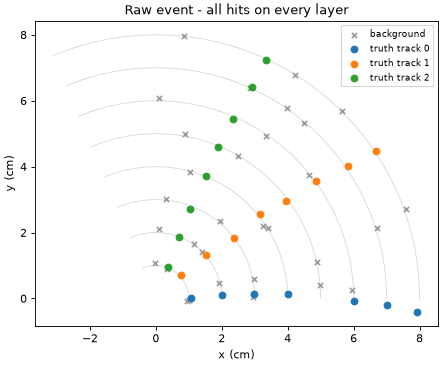

In [3]:
# Raw event display. `draw_layers` plots the detector's cylindrical layers as thin
# arcs; the hits come from the event (signal colored by truth track, background as
# grey x markers).
def draw_layers(ax, radii):
    theta = np.linspace(0, np.pi / 2 + 0.4, 200)
    for r in radii:
        ax.plot(r * np.cos(theta), r * np.sin(theta), color="0.85", lw=0.8, zorder=0)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_layers(ax, model.radii)
colors = plt.get_cmap("tab10")
for layer in range(len(event.hits)):
    hits, truth = event.hits[layer], event.truth[layer]
    is_background = truth < 0
    ax.scatter(hits[is_background, 0], hits[is_background, 1], s=22, c="0.6", marker="x",
               zorder=2, label="background" if layer == 0 else None)
    for track_id in range(event.n_tracks):
        mask = truth == track_id
        ax.scatter(hits[mask, 0], hits[mask, 1], s=36, color=colors(track_id), zorder=3,
                   label=f"truth track {track_id}" if layer == 0 else None)

ax.set_aspect("equal")
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
ax.set_title("Raw event - all hits on every layer")
ax.legend(fontsize=8, loc="upper right")
plt.show()


## Step 2 — Run the CKF

Wrap the model in `CombinatorialKalmanFilter`. Call `forward(...)` with the per-layer
hits. Each layer can have a different number of hits, so the hit lists are ragged (of
unequal length).

The table below lists the hyperparameters that control the search.

| Parameter | Default | Rule of thumb |
|---|---|---|
| `chi2_cut` | 9.21 | The $\chi^2$ gate for 2 measurements per layer (x, y), at 99% acceptance. A wrong degrees-of-freedom choice (for example $\chi^2(1) \to 6.63$) tightens the gate and drops real hits. |
| `max_candidates` | 8 | The beam width. Raise this value to recover more lost tracks. Lower this value to run faster. |
| `max_holes` | 2 | The number of missing layers the filter tolerates per track. Use 0 for dense, efficient detectors. |
| `min_hits` | 4 | The minimum number of layers a track needs. The filter rejects shorter track stubs. |
| `shared_hit_frac` | 0.3 | The hit overlap fraction above which the filter merges two candidates. |


In [4]:
from kalman.filters import CombinatorialKalmanFilter

ckf = CombinatorialKalmanFilter(model, max_candidates=8, max_holes=2, min_hits=4, shared_hit_frac=0.3)
tracks = ckf.forward(event.hits, layer_radii=event.radii)

print(f"chi2 gate       : {ckf.chi2_cut:.2f}")
print(f"candidates/seed : {len(ckf.candidates)}")
print(f"accepted tracks : {len(tracks)}\n")
for i, raw in enumerate(ckf.tracks_raw):
    truth_ids = [int(event.truth[layer][hit]) for (layer, hit) in raw.hit_ids]
    signal_ids = [truth_id for truth_id in truth_ids if truth_id >= 0]
    majority_id = max(set(signal_ids), key=signal_ids.count) if signal_ids else -1
    purity = signal_ids.count(majority_id) / len(truth_ids)
    print(f"  track {i}: {raw.n_hits} hits, chi2/ndf={raw.chi2/raw.n_hits:5.2f}, "
          f"majority truth={majority_id}, purity={purity:4.0%}, holes={raw.holes}")


chi2 gate       : 9.21
candidates/seed : 7
accepted tracks : 3

  track 0: 8 hits, chi2/ndf= 0.96, majority truth=2, purity= 88%, holes=0
  track 1: 8 hits, chi2/ndf= 1.15, majority truth=1, purity=100%, holes=0
  track 2: 7 hits, chi2/ndf= 0.28, majority truth=0, purity= 86%, holes=1


### Reconstructed Tracks

The CKF selects the correct hits from the mixed set. The plot draws each found track
as a colored line through its claimed hits. Rejected background hits stay grey.


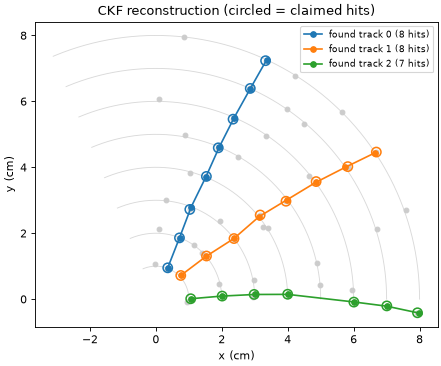

In [5]:
# CKF reconstruction. `tracks` is a KalmanRecordCollection (one KalmanRecord per found
# track). We overlay each track's posterior x-y path, with its claimed hits circled.
fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_layers(ax, model.radii)

# All hits, drawn faint, as background context.
for layer in range(len(event.hits)):
    hits = event.hits[layer]
    ax.scatter(hits[:, 0], hits[:, 1], s=18, c="0.8", zorder=1)

for i, rec in enumerate(tracks):
    position = rec.xk[:, :2]
    ax.plot(position[:, 0], position[:, 1], "-o", ms=5, color=colors(i), zorder=4,
            label=f"found track {i} ({len(rec)} hits)")
    claimed_hits = rec.zk
    ax.scatter(claimed_hits[:, 0], claimed_hits[:, 1], s=70, facecolors="none",
               edgecolors=colors(i), linewidths=1.4, zorder=3)

ax.set_aspect("equal")
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
ax.set_title("CKF reconstruction (circled = claimed hits)")
ax.legend(fontsize=8, loc="upper right")
plt.show()


## Step 3 — Smooth the Fitted Tracks

Each track, once its hits are assigned, is a standard Kalman fit. The RTS smoother
refines the state estimate at every layer. It uses information from the whole track,
not only the hits seen so far.

Call `backward()` to get the smoothed records.


In [6]:
smoothed = ckf.backward()  # RTS-smooth each accepted track (uses the forward pass above)
for i, (filtered_track, smoothed_track) in enumerate(zip(tracks, smoothed)):
    # Mean position uncertainty (trace of the 2x2 position block), before vs. after smoothing.
    sigma_filtered = np.sqrt(np.trace(filtered_track.Pk[:, :2, :2], axis1=1, axis2=2)).mean()
    sigma_smoothed = np.sqrt(np.trace(smoothed_track.Pk[:, :2, :2], axis1=1, axis2=2)).mean()
    print(f"track {i}: mean position sigma  filtered={sigma_filtered:.4f}  "
          f"smoothed={sigma_smoothed:.4f} cm")


track 0: mean position sigma  filtered=0.0463  smoothed=0.0323 cm
track 1: mean position sigma  filtered=0.0458  smoothed=0.0323 cm
track 2: mean position sigma  filtered=0.0498  smoothed=0.0361 cm
